# 04 – Research Question 2: Predicting Pollutant Concentrations with Linear Regression

**Project:** Analyzing Air Quality Patterns Across Texas (CSE 4334 Data Mining)

### Research Question 2
**Can we use historical air quality data to predict pollutant concentrations?**

### Which pollutant do we predict?
We checked both cleaned files before choosing:

| | Ozone | PM2.5 |
|---|---|---|
| Site-days | 126,078 | 76,660 |
| Monitoring sites | 76 | 57 |
| Typical site coverage | most sites have ~1,700+ days | several sites have large gaps |
| Day-to-day behavior | smooth, strong seasonal pattern | mostly smooth, but sudden spikes (fireworks, smoke, dust) |

**Our choice:** ozone is the **main** target. It has more sites, more complete records, and its daily value (the 8-hour maximum, "MDA8") is exactly what the EPA ozone standard and the AQI use.
We then repeat the **same steps for PM2.5** in Section 9, so we can say whether the method works for both pollutants.

### The plan
1. Choose the target (what we predict) and the inputs (what we use to predict it)
2. Build the inputs using **only past days**, so the model never "sees the answer"
3. Split the data by time: **train on 2020–2023, test on 2024**
4. Fit a linear regression and compare it to two simple baselines
5. Measure accuracy with **MAE, RMSE and R²**, and look at where the model makes mistakes

We use the cleaned files from `02_data_cleaning.ipynb` and **do not change them**.

## 0. Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# the notebook lives in notebooks/, the data folders are one level up
DATA = ".."
FIGS = f"{DATA}/EDA_Results/RQ2_regression"
os.makedirs(FIGS, exist_ok=True)

# colors used in every chart
ACTUAL_COLOR = "#2a78d6"     # blue   = actual values
PREDICT_COLOR = "#eb6834"    # orange = model predictions
BASELINE_COLOR = "#a3a29b"   # gray   = simple baselines

In [2]:
oz = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_Ozone_Clean.csv")
print("Ozone:", oz.shape)
oz.head()

Ozone: (126078, 13)


,site_id,date_local,year,county_name,city_name,local_site_name,cbsa_name,latitude,longitude,ozone_mda8_ppm,ozone_daily_mean_ppm,ozone_aqi,percent_complete
0,48-027-1045,2020-01-01,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.032,0.027588,30,100.0
1,48-027-1045,2020-01-02,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.016,0.010176,15,100.0
2,48-027-1045,2020-01-03,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.030,0.026824,28,100.0
3,48-027-1045,2020-01-04,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.039,0.027000,36,100.0
4,48-027-1045,2020-01-05,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.042,0.029706,39,100.0


## 1. What are we trying to predict? (the dependent variable)

In regression there are two kinds of variables:

- The **dependent variable** (also called the *target*, or **y**) is what we want to predict. It "depends" on the other variables.
- The **independent variables** (also called *inputs* or *features*, or **X**) are the information we use to make the prediction.

**Our dependent variable:** the ozone level at a monitoring site on a given day (`ozone_mda8_ppm`, the daily maximum 8-hour average).

The values are in ppm (parts per million), so they are small numbers like 0.038. To make them easier to read and talk about, we convert to **ppb** (parts per billion) by multiplying by 1,000 — so 0.038 ppm becomes 38 ppb. This is only a unit change inside the notebook; the cleaned file is not changed. For reference, the EPA ozone standard is **70 ppb**.

In [3]:
oz["date"] = pd.to_datetime(oz["date_local"])
oz["ozone_ppb"] = oz["ozone_mda8_ppm"] * 1000

# sort so each site's days are in order (needed for the next step)
oz = oz.sort_values(["site_id", "date"]).reset_index(drop=True)

oz["ozone_ppb"].describe().round(1)

count    126078.0
mean         39.0
std          13.1
min          -1.0
25%          30.0
50%          38.0
75%          47.0
max         114.0
Name: ozone_ppb, dtype: float64

The typical (median) ozone day is about 38 ppb, and most days fall between 30 and 47 ppb. The highest days go above 100 ppb.

## 2. Building the inputs (the independent variables)

**What are we doing?** For every site and day, we create three inputs from that site's **earlier** days:

| Input | Meaning | Why it might help |
|---|---|---|
| `ozone_yesterday` | the site's ozone value on the day before | air quality changes slowly, so yesterday is usually close to today |
| `ozone_2days_ago` | the site's value two days before | checks whether a slightly longer memory helps |
| `ozone_past7_avg` | the average of the site's values over the 7 days before | shows the recent "normal" level and smooths out one unusual day |

**Why only past days?** The model should only use information that would actually be known when the prediction is made. Imagine making the prediction the evening before: we already know yesterday's and last week's ozone, but **not** today's. If we let the model use anything from the day it is predicting (for example, today's AQI or today's daily mean), it would be "seeing the answer". That is called **data leakage**, and it makes a model look much better than it really is.

**One detail:** some sites have missing days. If a site has no data on June 9, the row before June 10 is June 8 — that is **not** "yesterday". So we only fill in `ozone_yesterday` when the previous row really is one day earlier (and the same for two days).

In [4]:
# value and date of the previous row for the same site
prev1_value = oz.groupby("site_id")["ozone_ppb"].shift(1)
prev1_date = oz.groupby("site_id")["date"].shift(1)

# only keep it if the previous row is really the day before
oz["ozone_yesterday"] = prev1_value.where(oz["date"] - prev1_date == pd.Timedelta(days=1))

# same idea for two days ago
prev2_value = oz.groupby("site_id")["ozone_ppb"].shift(2)
prev2_date = oz.groupby("site_id")["date"].shift(2)
oz["ozone_2days_ago"] = prev2_value.where(oz["date"] - prev2_date == pd.Timedelta(days=2))

For the 7-day average we use pandas' `rolling("7D")`. For each row it looks at that site's values in the **7 calendar days before** the date.
`closed="left"` means **today is not included** (no leakage), and `min_periods=5` means we need at least 5 of those 7 days to have data, otherwise the average is left empty.

In [5]:
past7 = oz.groupby("site_id").rolling("7D", on="date", closed="left", min_periods=5)["ozone_ppb"].mean()

# the data is sorted by site and date, so the results line up row by row
oz["ozone_past7_avg"] = past7.values

In [6]:
# check one row by hand: the 7-day average should equal the mean of the 7 days before it
row = oz.iloc[500]
week_before = oz[(oz["site_id"] == row["site_id"]) &
                 (oz["date"] < row["date"]) &
                 (oz["date"] >= row["date"] - pd.Timedelta(days=7))]
print("Site:", row["site_id"], "| date:", row["date"].date())
print("7-day average in our column:", round(row["ozone_past7_avg"], 3))
print("Mean of the 7 days before:  ", round(week_before["ozone_ppb"].mean(), 3))

Site: 48-027-1045 | date: 2021-06-07
7-day average in our column: 36.143
Mean of the 7 days before:   36.143


In [7]:
oz[["site_id", "date", "ozone_ppb", "ozone_yesterday", "ozone_2days_ago", "ozone_past7_avg"]].iloc[495:503]

,site_id,date,ozone_ppb,ozone_yesterday,ozone_2days_ago,ozone_past7_avg
495,48-027-1045,2021-06-02,44.0,35.0,40.0,36.000000
496,48-027-1045,2021-06-03,22.0,44.0,35.0,38.285714
497,48-027-1045,2021-06-04,37.0,22.0,44.0,36.857143
498,48-027-1045,2021-06-05,43.0,37.0,22.0,37.142857
499,48-027-1045,2021-06-06,32.0,43.0,37.0,36.571429
500,48-027-1045,2021-06-07,40.0,32.0,43.0,36.142857
501,48-027-1045,2021-06-08,29.0,40.0,32.0,36.142857
502,48-027-1045,2021-06-09,34.0,29.0,40.0,35.285714


Reading the table: on each row, `ozone_yesterday` is the `ozone_ppb` value from the row above it, and `ozone_past7_avg` is the average of the rows before it — never the current row. This confirms the inputs only use past information.

Rows that don't have all three inputs (the first days at each site, or days right after a gap) can't be used, so we drop them:

In [8]:
features = ["ozone_yesterday", "ozone_2days_ago", "ozone_past7_avg"]
target = "ozone_ppb"

print("Missing values in each input:")
print(oz[features].isna().sum())

oz_model = oz.dropna(subset=features).copy()
print()
print("Rows before:", len(oz), "| rows with all inputs:", len(oz_model),
      f"({len(oz_model) / len(oz) * 100:.1f}% kept)")

Missing values in each input:
ozone_yesterday    3159
ozone_2days_ago    6158
ozone_past7_avg    3176
dtype: int64

Rows before: 126078 | rows with all inputs: 118262 (93.8% kept)


We keep about 94% of the site-days, which is plenty for a regression.

## 3. Training and testing data

**What are we doing?** We split the data into two parts:
- **Training data** — the model learns from these rows (it finds the best formula).
- **Testing data** — rows the model has **never seen**. We use them to check how well it predicts.

**Why split by time instead of randomly?** In real life we predict the **future** from the past. A random split would mix 2024 days into training and then "predict" 2023 days, which can't happen in practice, and it would let the model learn from days right next to the test days. So we use a **time-based split**:

- **Train:** 2020, 2021, 2022, 2023
- **Test:** 2024 (the latest year)

In [9]:
train = oz_model[oz_model["year"] <= 2023]
test = oz_model[oz_model["year"] == 2024]

X_train = train[features]
y_train = train[target]
X_test = test[features]
y_test = test[target]

split_table = pd.DataFrame({
    "years": ["2020–2023", "2024"],
    "rows": [len(train), len(test)],
    "sites": [train["site_id"].nunique(), test["site_id"].nunique()],
    "average ozone (ppb)": [round(y_train.mean(), 1), round(y_test.mean(), 1)],
}, index=["train", "test"])
split_table

,years,rows,sites,average ozone (ppb)
train,2020–2023,94914,76,38.8
test,2024,23348,73,40.4


About 80% of the rows are for training and 20% for testing. 73 of the 76 sites have data in 2024. Notice that 2024 had slightly **higher** ozone on average (40.4 ppb) than 2020–2023 (38.8 ppb) — this will matter for one of the baselines.

**Is using Dec 31, 2023 to predict Jan 1, 2024 leakage?** No. The inputs for the first test days come from late 2023, but those values would be known on Jan 1. Leakage only happens if the model uses information from the day it's predicting (or later).

## 4. Baselines: what does "good" mean?

A model is only useful if it beats a **simple guess**. We compare against two baselines:

1. **Average baseline:** always predict the average ozone from the training years (the same number every day). This is the "know nothing" guess.
2. **"Same as yesterday" baseline:** predict that today's ozone equals yesterday's ozone. This is a strong, common-sense guess and the real test for our model.

Neither baseline needs any training.

In [10]:
baseline_average = np.full(len(test), y_train.mean())
baseline_yesterday = test["ozone_yesterday"]

print("Average baseline predicts", round(y_train.mean(), 1), "ppb every day")

Average baseline predicts 38.8 ppb every day


## 5. Training the linear regression

**What is linear regression?** It finds the straight-line formula that best fits the training data:

$$\text{predicted ozone} = b_0 + b_1 \cdot \text{yesterday} + b_2 \cdot \text{2 days ago} + b_3 \cdot \text{past 7-day avg}$$

- $b_0$ is the **intercept** (the starting value)
- $b_1, b_2, b_3$ are the **coefficients** (how much each input counts)

"Best fit" means the formula that makes the squared errors on the training data as small as possible ("least squares").

**Why linear regression?** It's simple, fast, and — most importantly — **easy to explain**: we can read the coefficients and see what the model learned.

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

coef_table = pd.DataFrame({"coefficient": model.coef_.round(3)}, index=features)
print("Intercept (b0):", round(model.intercept_, 2))
coef_table

Intercept (b0): 7.69


,coefficient
ozone_yesterday,0.625
ozone_2days_ago,-0.035
ozone_past7_avg,0.212


So the formula the model learned is:

**predicted ozone = 7.69 + 0.625 × yesterday + (âˆ’0.035) × 2 days ago + 0.212 × past 7-day average**

**What does this mean?**
- **Yesterday matters most.** Each 1 ppb increase in yesterday's ozone raises today's prediction by about 0.63 ppb.
- **The past week also helps** (0.21 per ppb). It pulls the prediction toward the site's recent normal level.
- **Two days ago adds almost nothing** (about −0.04). Once the model knows yesterday and the weekly average, the value from two days ago gives no new information. It's fine to keep it — the coefficient simply tells us it isn't useful.
- The coefficients add up to less than 1 (0.63 + 0.21 − 0.04 ≈ 0.80), and the intercept is positive. This means the model **doesn't fully trust** a very high or very low day to repeat; it predicts that tomorrow will move partly back toward average. That's why it can beat "same as yesterday".

In [12]:
y_pred = model.predict(X_test)

# put actual and predicted side by side for a few test days
compare = test[["site_id", "date", "ozone_ppb"]].copy()
compare["predicted_ppb"] = y_pred
compare["error_ppb"] = compare["ozone_ppb"] - compare["predicted_ppb"]
compare.head(8).round(1)

,site_id,date,ozone_ppb,predicted_ppb,error_ppb
1414,48-027-1045,2024-01-01,26.0,38.3,-12.3
1415,48-027-1045,2024-01-02,23.0,29.3,-6.3
1416,48-027-1045,2024-01-03,23.0,27.7,-4.7
1417,48-027-1045,2024-01-04,37.0,27.5,9.5
1418,48-027-1045,2024-01-05,32.0,36.5,-4.5
1419,48-027-1045,2024-01-06,27.0,33.0,-6.0
1420,48-027-1045,2024-01-07,38.0,29.7,8.3
1421,48-027-1045,2024-01-08,36.0,36.7,-0.7


**Actual vs. predicted:** the **actual** value is what the monitor really measured; the **predicted** value is what our formula guessed using only the days before. The **error** is actual − predicted: positive means the model guessed too low, negative means too high.

## 6. How accurate is the model? (MAE, RMSE, R²)

We measure accuracy on the **2024 test data** with three common metrics:

- **MAE (Mean Absolute Error):** the average size of the errors, ignoring + or −. In the same units as ozone (ppb). Lower is better.
- **RMSE (Root Mean Squared Error):** squares the errors first, averages them, then takes the square root. Big misses count extra, so RMSE is always ≥ MAE. Also in ppb. Lower is better.
- **R² (R-squared):** the share of the day-to-day variation in ozone that the model explains. 1 = perfect, 0 = no better than always guessing the average, below 0 = worse than the average. Higher is better.

In [13]:
results = pd.DataFrame({
    "MAE (ppb)": [mean_absolute_error(y_test, baseline_average),
                  mean_absolute_error(y_test, baseline_yesterday),
                  mean_absolute_error(y_test, y_pred)],
    "RMSE (ppb)": [np.sqrt(mean_squared_error(y_test, baseline_average)),
                   np.sqrt(mean_squared_error(y_test, baseline_yesterday)),
                   np.sqrt(mean_squared_error(y_test, y_pred))],
    "R²": [r2_score(y_test, baseline_average),
           r2_score(y_test, baseline_yesterday),
           r2_score(y_test, y_pred)],
}, index=["Average baseline", "Same as yesterday", "Linear regression"])
results.round(3)

,MAE (ppb),RMSE (ppb),R²
Average baseline,10.425,13.349,-0.015
Same as yesterday,7.484,10.079,0.421
Linear regression,6.957,9.214,0.516


In [14]:
# compare training and testing R² to check for overfitting
print("R² on training data (2020–2023):", round(r2_score(y_train, model.predict(X_train)), 3))
print("R² on testing data  (2024):     ", round(r2_score(y_test, y_pred), 3))

R² on training data (2020–2023): 0.519
R² on testing data  (2024):      0.516


**What do our results mean?**

- **MAE = 6.96 ppb.** On a typical 2024 day, our prediction was off by about 7 ppb. Since an average day is about 40 ppb, that's an error of roughly 17%.
- **RMSE = 9.21 ppb.** It's higher than the MAE, which tells us there are some **large misses** that the squaring makes stand out (we look at them in Section 8).
- **R² = 0.516.** The model explains about **52% of the day-to-day variation** in ozone. The other ~48% comes from things the model doesn't know — mainly weather (sunshine, temperature, wind), which drives ozone formation.

**Compared to the baselines:**
- The **average baseline** has R² ≈ âˆ’0.015 — slightly *below* zero because 2024 was a bit higher than the training average. This is the "know nothing" level.
- **"Same as yesterday"** already gets R² = 0.421, so past values clearly contain useful information.
- **Linear regression beats both.** Compared with "same as yesterday", it lowers MAE from 7.48 to 6.96 ppb (about 7% smaller) and raises R² from 0.421 to 0.516.

**Overfitting check:** training R² (0.519) and testing R² (0.516) are almost the same, so the model isn't just memorizing the training years — it works just as well on a year it has never seen.

## 7. Visualizing the predictions

### 7.1 Actual vs. predicted over time (one site)
To see what the predictions look like, we plot 2024 for one site with almost complete data: **Frisco (Dallas–Fort Worth area)**.

Frisco - 363 test days


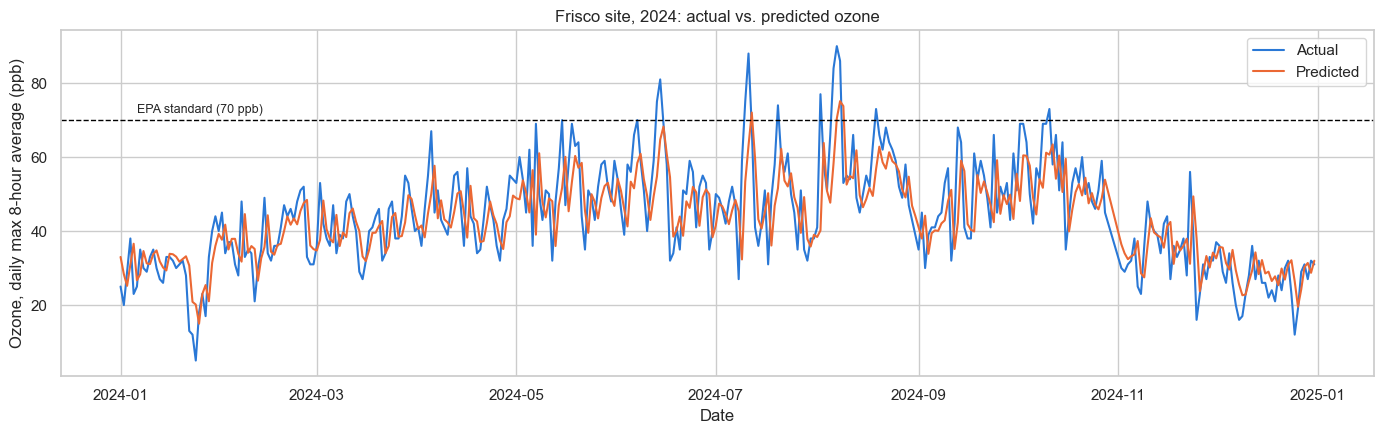

In [15]:
site = "48-085-0005"
one_site = compare[compare["site_id"] == site]
print(test[test["site_id"] == site]["local_site_name"].iloc[0], "-", len(one_site), "test days")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(one_site["date"], one_site["ozone_ppb"], color=ACTUAL_COLOR, linewidth=1.5, label="Actual")
ax.plot(one_site["date"], one_site["predicted_ppb"], color=PREDICT_COLOR, linewidth=1.5, label="Predicted")
ax.axhline(70, color="black", linestyle="--", linewidth=1)
ax.text(one_site["date"].iloc[5], 72, "EPA standard (70 ppb)", fontsize=9)
ax.set_title("Frisco site, 2024: actual vs. predicted ozone")
ax.set_xlabel("Date")
ax.set_ylabel("Ozone, daily max 8-hour average (ppb)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_actual_vs_predicted_frisco_2024.png", dpi=150)
plt.show()

**What does this show?** The orange line follows the blue line's overall pattern — low in winter, higher in spring and late summer — so the model captures the **seasonal trend**. But the orange line is **smoother** and usually **one day late**: when ozone suddenly jumps, the model only reacts the next day, because it only knows past values. It rarely reaches the peaks above the 70 ppb line.

### 7.2 Actual vs. predicted for all 2024 test days
Each dot is one site-day. If the predictions were perfect, every dot would be on the dashed diagonal line.

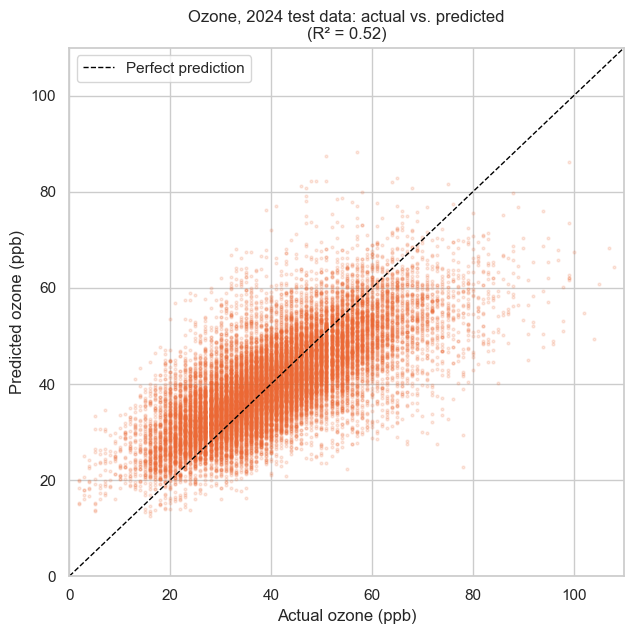

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(y_test, y_pred, s=4, alpha=0.15, color=PREDICT_COLOR)
ax.plot([0, 110], [0, 110], color="black", linestyle="--", linewidth=1, label="Perfect prediction")
ax.set_xlim(0, 110)
ax.set_ylim(0, 110)
ax.set_title(f"Ozone, 2024 test data: actual vs. predicted\n(R² = {r2_score(y_test, y_pred):.2f})")
ax.set_xlabel("Actual ozone (ppb)")
ax.set_ylabel("Predicted ozone (ppb)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_actual_vs_predicted_scatter.png", dpi=150)
plt.show()

**What does this show?** The dots follow the diagonal, so higher actual ozone generally gets a higher prediction. But the cloud is **flatter** than the diagonal: on the right side (high actual ozone), most dots are **below** the line, meaning the model predicts too low on high days. On the left side (very clean days) the dots are above the line — it predicts too high. This is the "pull toward average" we saw in the coefficients.

### 7.3 How big are the errors?

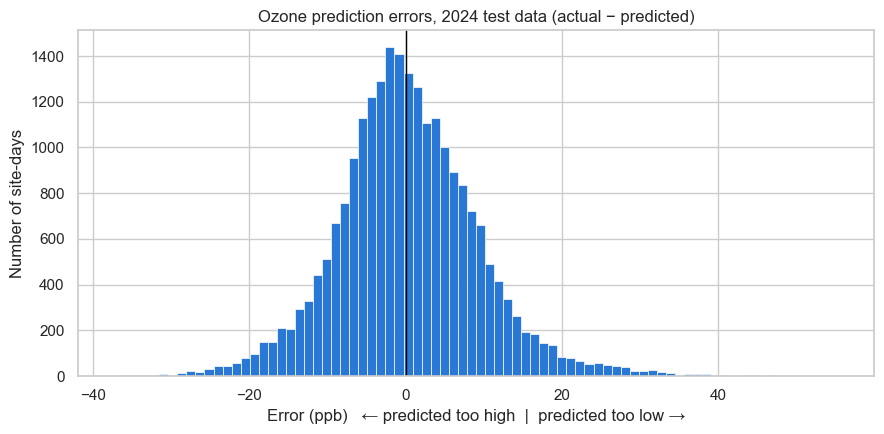

Average error: 0.3 ppb
Days within ±5 ppb:  46%
Days within ±10 ppb: 77%


In [17]:
errors = y_test - y_pred

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(errors, bins=80, color=ACTUAL_COLOR, edgecolor="white", linewidth=0.5)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Ozone prediction errors, 2024 test data (actual − predicted)")
ax.set_xlabel("Error (ppb)   ← predicted too high  |  predicted too low →")
ax.set_ylabel("Number of site-days")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_error_histogram.png", dpi=150)
plt.show()

print("Average error:", round(errors.mean(), 2), "ppb")
print("Days within ±5 ppb: ", f"{(errors.abs() <= 5).mean() * 100:.0f}%")
print("Days within ±10 ppb:", f"{(errors.abs() <= 10).mean() * 100:.0f}%")

**What does this show?** The errors are centered near zero (average error ≈ 0.3 ppb), so the model isn't consistently too high or too low overall. About **46%** of days are within ±5 ppb and **77%** within ±10 ppb. The right tail is longer than the left: the biggest misses are days where ozone was much **higher** than predicted.

### 7.4 Model vs. baselines

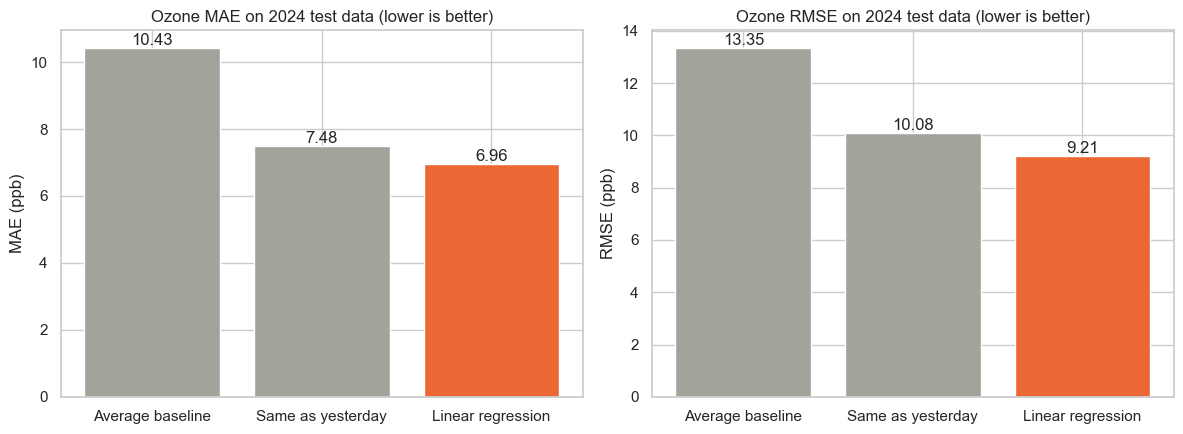

In [18]:
methods = results.index.tolist()
bar_colors = [BASELINE_COLOR, BASELINE_COLOR, PREDICT_COLOR]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ["MAE (ppb)", "RMSE (ppb)"]):
    bars = ax.bar(methods, results[metric], color=bar_colors)
    ax.bar_label(bars, fmt="%.2f")
    ax.set_title(f"Ozone {metric.split()[0]} on 2024 test data (lower is better)")
    ax.set_ylabel(metric)
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_model_vs_baselines.png", dpi=150)
plt.show()

**What does this show?** Linear regression (orange) has the smallest errors. The big improvement is from the average baseline to anything that uses past values. The improvement over "same as yesterday" is real but smaller — about 0.5 ppb in MAE and 0.9 ppb in RMSE.

## 8. Where does the model struggle? High-ozone days

The days that matter most for health are the **high-ozone days** — above the EPA standard of 70 ppb. Let's check how the model does on them.

In [19]:
high = compare["ozone_ppb"] >= 70
high_table = pd.DataFrame({
    "site-days": [high.sum(), (~high).sum()],
    "average actual (ppb)": [compare.loc[high, "ozone_ppb"].mean(), compare.loc[~high, "ozone_ppb"].mean()],
    "average predicted (ppb)": [compare.loc[high, "predicted_ppb"].mean(), compare.loc[~high, "predicted_ppb"].mean()],
    "MAE (ppb)": [compare.loc[high, "error_ppb"].abs().mean(), compare.loc[~high, "error_ppb"].abs().mean()],
}, index=["Actual ≥ 70 ppb", "Actual < 70 ppb"])
print("High-ozone days that the model also predicted ≥ 70 ppb:",
      (compare.loc[high, "predicted_ppb"] >= 70).sum(), "of", high.sum())
high_table.round(1)

High-ozone days that the model also predicted ≥ 70 ppb: 25 of 572


,site-days,average actual (ppb),average predicted (ppb),MAE (ppb)
Actual ≥ 70 ppb,572,77.1,55.7,21.4
Actual < 70 ppb,22776,39.5,39.7,6.6


**What does this mean?** This is the model's biggest weakness. On the 572 test site-days with ozone ≥ 70 ppb, the actual average was **77.1 ppb** but the model predicted only **55.7 ppb** on average — an average miss of about **21 ppb**. It predicted ≥ 70 ppb on only **25 of those 572 days**.

The reason: high-ozone days are caused mostly by **weather** (hot, sunny, calm days), which often arrive suddenly. A model that only knows past ozone values can't see them coming. So the model is good for predicting **typical** levels, but it should **not** be used as an ozone alert system without weather data.

## 9. Same steps for PM2.5

Now we repeat the exact same method for PM2.5 to see if past values work for the other pollutant too:
- **Target:** daily PM2.5 at a site (`pm25_ugm3`, in µg/m³ — micrograms per cubic meter)
- **Inputs:** PM2.5 yesterday, 2 days ago, and the past 7-day average (same rules: past days only)
- **Split:** train 2020–2023, test 2024

In [20]:
pm = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_PM25_Clean.csv")
pm["date"] = pd.to_datetime(pm["date_local"])
pm = pm.sort_values(["site_id", "date"]).reset_index(drop=True)

prev1_value = pm.groupby("site_id")["pm25_ugm3"].shift(1)
prev1_date = pm.groupby("site_id")["date"].shift(1)
pm["pm25_yesterday"] = prev1_value.where(pm["date"] - prev1_date == pd.Timedelta(days=1))

prev2_value = pm.groupby("site_id")["pm25_ugm3"].shift(2)
prev2_date = pm.groupby("site_id")["date"].shift(2)
pm["pm25_2days_ago"] = prev2_value.where(pm["date"] - prev2_date == pd.Timedelta(days=2))

past7 = pm.groupby("site_id").rolling("7D", on="date", closed="left", min_periods=5)["pm25_ugm3"].mean()
pm["pm25_past7_avg"] = past7.values

pm_features = ["pm25_yesterday", "pm25_2days_ago", "pm25_past7_avg"]
pm_model = pm.dropna(subset=pm_features).copy()
print("Rows before:", len(pm), "| rows with all inputs:", len(pm_model),
      f"({len(pm_model) / len(pm) * 100:.1f}% kept)")

Rows before: 76660 | rows with all inputs: 71696 (93.5% kept)


We keep about the same share of rows as for ozone (93.5%).

In [21]:
pm_train = pm_model[pm_model["year"] <= 2023]
pm_test = pm_model[pm_model["year"] == 2024]
print("Train rows:", len(pm_train), "| test rows:", len(pm_test),
      "| test sites:", pm_test["site_id"].nunique())

pm_reg = LinearRegression()
pm_reg.fit(pm_train[pm_features], pm_train["pm25_ugm3"])
pm_pred = pm_reg.predict(pm_test[pm_features])

print("Intercept (b0):", round(pm_reg.intercept_, 2))
pd.DataFrame({"coefficient": pm_reg.coef_.round(3)}, index=pm_features)

Train rows: 55086 | test rows: 16610 | test sites: 53
Intercept (b0): 2.34


,coefficient
pm25_yesterday,0.597
pm25_2days_ago,-0.118
pm25_past7_avg,0.258


In [22]:
pm_y_test = pm_test["pm25_ugm3"]
pm_baseline_average = np.full(len(pm_test), pm_train["pm25_ugm3"].mean())
pm_baseline_yesterday = pm_test["pm25_yesterday"]

pm_results = pd.DataFrame({
    "MAE (µg/m³)": [mean_absolute_error(pm_y_test, pm_baseline_average),
                    mean_absolute_error(pm_y_test, pm_baseline_yesterday),
                    mean_absolute_error(pm_y_test, pm_pred)],
    "RMSE (µg/m³)": [np.sqrt(mean_squared_error(pm_y_test, pm_baseline_average)),
                     np.sqrt(mean_squared_error(pm_y_test, pm_baseline_yesterday)),
                     np.sqrt(mean_squared_error(pm_y_test, pm_pred))],
    "R²": [r2_score(pm_y_test, pm_baseline_average),
           r2_score(pm_y_test, pm_baseline_yesterday),
           r2_score(pm_y_test, pm_pred)],
}, index=["Average baseline", "Same as yesterday", "Linear regression"])

print("Average PM2.5 in the test year:", round(pm_y_test.mean(), 1), "µg/m³")
print("Standard deviation of PM2.5 - train:", round(pm_train["pm25_ugm3"].std(), 2), "| test:", round(pm_y_test.std(), 2))
print("R² on training data:", round(r2_score(pm_train["pm25_ugm3"], pm_reg.predict(pm_train[pm_features])), 3))
pm_results.round(3)

Average PM2.5 in the test year: 9.7 µg/m³
Standard deviation of PM2.5 - train: 5.23 | test: 7.02
R² on training data: 0.421


,MAE (µg/m³),RMSE (µg/m³),R²
Average baseline,4.324,7.077,-0.015
Same as yesterday,3.344,5.494,0.388
Linear regression,3.072,4.954,0.503


In [23]:
# high PM2.5 days: the EPA daily standard is 35 µg/m³
pm_high = pm_y_test >= 35
print("Test site-days with PM2.5 ≥ 35 µg/m³:", pm_high.sum())
print("Average actual on those days:   ", round(pm_y_test[pm_high].mean(), 1), "µg/m³")
print("Average predicted on those days:", round(pm_pred[pm_high.values].mean(), 1), "µg/m³")

Test site-days with PM2.5 ≥ 35 µg/m³: 219
Average actual on those days:    45.5 µg/m³
Average predicted on those days: 26.7 µg/m³


**What does this mean?**
- The PM2.5 model follows the **same pattern** as ozone: yesterday counts most (0.597), the past week helps (0.258), and two days ago adds little (âˆ’0.118).
- **MAE = 3.07 µg/m³** and **RMSE = 4.95 µg/m³**, with an average 2024 level of 9.7 µg/m³. The RMSE is much larger than the MAE, which means PM2.5 has some **very large misses** — sudden spikes like fireworks, smoke or dust.
- **R² = 0.503**: the model explains about 50% of the day-to-day variation, again better than "same as yesterday" (R² = 0.388) and much better than the average baseline (R² = âˆ’0.015).
- **Why is the test R² (0.503) higher than the training R² (0.421)?** This is not overfitting (overfitting would be the opposite). R² measures how much of the variation is explained, and 2024 PM2.5 **varied more** than 2020–2023 (standard deviation 7.02 vs. 5.23 µg/m³), with many more high days. When high levels last several days, yesterday's value warns the model, so a larger share of the variation gets explained — even though the errors in µg/m³ are not small.
- Like ozone, it misses the high days: on the 219 test site-days with PM2.5 ≥ 35 µg/m³, the actual average was 45.5 µg/m³ but the predicted average was only 26.7 µg/m³.

## 10. Comparing both pollutants

MAE and RMSE use different units for ozone (ppb) and PM2.5 (µg/m³), so we can't compare them directly. **R² has no units**, so we use it to compare.

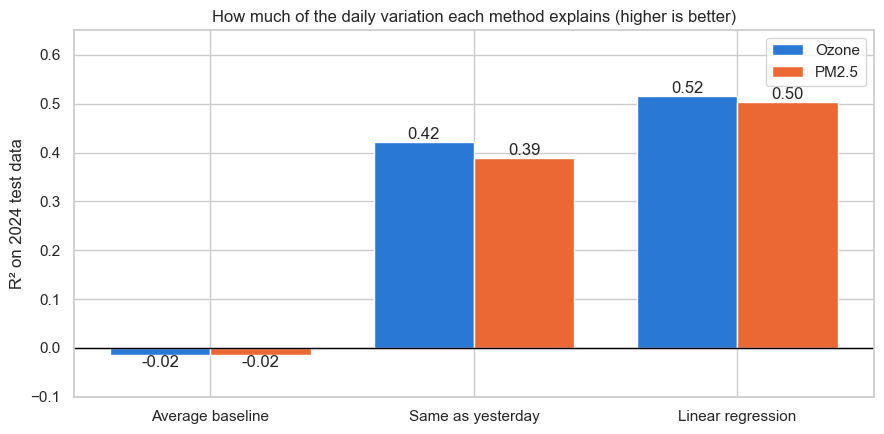

In [24]:
r2_compare = pd.DataFrame({
    "Ozone": results["R²"],
    "PM2.5": pm_results["R²"],
})

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(r2_compare.index))
width = 0.38
bars1 = ax.bar(x - width / 2, r2_compare["Ozone"], width, color=ACTUAL_COLOR, label="Ozone")
bars2 = ax.bar(x + width / 2, r2_compare["PM2.5"], width, color=PREDICT_COLOR, label="PM2.5")
ax.bar_label(bars1, fmt="%.2f")
ax.bar_label(bars2, fmt="%.2f")
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(r2_compare.index)
ax.set_ylim(-0.1, 0.65)
ax.set_ylabel("R² on 2024 test data")
ax.set_title("How much of the daily variation each method explains (higher is better)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIGS}/r2_comparison_ozone_pm25.png", dpi=150)
plt.show()

**What does this show?** Both pollutants tell the same story: the average baseline explains nothing (R² ≈ 0), using yesterday's value explains about 40%, and linear regression with three past-value inputs explains about half (0.516 for ozone, 0.503 for PM2.5). Ozone is predicted slightly better than PM2.5.

In [25]:
# save the final results tables
summary = pd.concat([results.round(3).add_prefix("Ozone "), pm_results.round(3).add_prefix("PM2.5 ")], axis=1)
summary.to_csv(f"{FIGS}/rq2_results.csv")
summary

,Ozone MAE (ppb),Ozone RMSE (ppb),Ozone R²,PM2.5 MAE (µg/m³),PM2.5 RMSE (µg/m³),PM2.5 R²
Average baseline,10.425,13.349,-0.015,4.324,7.077,-0.015
Same as yesterday,7.484,10.079,0.421,3.344,5.494,0.388
Linear regression,6.957,9.214,0.516,3.072,4.954,0.503


## Research Question 2: Presentation Notes

**Research question:** Can we use historical air quality data to predict pollutant concentrations?

**Data we used**
- The cleaned EPA daily files from `02_data_cleaning.ipynb`: one value per monitoring site per day, Texas, 2020–2024
- Ozone: daily maximum 8-hour average (MDA8), 76 sites, converted to ppb
- PM2.5: daily average, 57 sites, in µg/m³

**Why linear regression?**
- It's the simplest regression model and easy to explain: we can read exactly how much each input counts
- It's a good first test of the question: if past values can predict future values, even a straight-line model should show it

**What we predicted (dependent variable):** the pollutant level at a site on a given day

**What we used to predict it (independent variables):** the same site's value **yesterday**, **two days ago**, and its **average over the past 7 days**
- We only used information from **before** the day being predicted, so there is no data leakage
- If a site was missing a day, we did not treat the older day as "yesterday"

**How we trained and tested**
- **Time-based split:** trained on 2020–2023, tested on 2024 — the model is judged on a year it never saw, like a real forecast
- Compared against two baselines: always predicting the training average, and "today = yesterday"

**Our results (2024 test data)**

| | MAE | RMSE | R² |
|---|---|---|---|
| Ozone – average baseline | 10.43 ppb | 13.35 ppb | âˆ’0.015 |
| Ozone – same as yesterday | 7.48 ppb | 10.08 ppb | 0.421 |
| **Ozone – linear regression** | **6.96 ppb** | **9.21 ppb** | **0.516** |
| PM2.5 – average baseline | 4.32 µg/m³ | 7.08 µg/m³ | âˆ’0.015 |
| PM2.5 – same as yesterday | 3.34 µg/m³ | 5.49 µg/m³ | 0.388 |
| **PM2.5 – linear regression** | **3.07 µg/m³** | **4.95 µg/m³** | **0.503** |

**What the results tell us**
- Ozone predictions were off by about 7 ppb on a typical day (average day ≈ 40 ppb)
- The model explains about half of the day-to-day variation (R² ≈ 0.5) for both pollutants
- It beats both baselines, including the strong "same as yesterday" guess
- Training and testing R² are almost equal, so the model isn't overfitting
- Yesterday's value is the most important input; the value from two days ago adds almost nothing

**Did historical data help?** **Yes, partly.** Past values clearly carry information — they take us from R² ≈ 0 to R² ≈ 0.5. But half of the variation is still unexplained.

**Important limitations**
- **Misses high-pollution days:** on ozone days ≥ 70 ppb the model predicted 55.7 ppb on average vs. 77.1 ppb actual, and caught only 25 of 572 such days
- **No weather data:** temperature, sunlight and wind drive ozone and PM2.5, and they are not in our dataset
- It reacts **one day late** to sudden changes
- One model for all sites — it doesn't learn site-specific differences
- Assumes yesterday's measurement is available in time; in real life EPA data can be delayed
- Tested on one year (2024) only

**Likely professor questions**
- *Why not a random train/test split?* — Because we're predicting the future. A random split would let the model train on days after the ones it's tested on.
- *How do you know there's no leakage?* — Every input comes from earlier days; the 7-day average excludes the current day (`closed="left"`), and we checked a row by hand.
- *Why is the average baseline's R² negative?* — 2024 had slightly higher ozone than 2020–2023, so the training average was a little off for every test day.
- *Why does the model beat "same as yesterday"?* — It learned to pull extreme days back toward normal (coefficients add up to less than 1), and the weekly average smooths out one unusual day.
- *How could it be improved?* — Add weather variables (temperature, wind) or day-of-year/season, and treat sites separately.

### 60–75 second presentation script

> "Our second research question was: can we use historical air quality data to predict pollutant concentrations? We used linear regression to predict the daily ozone level at each Texas monitoring site, and we repeated the same steps for PM2.5.
>
> For inputs, we only used information that would be known ahead of time: the site's value yesterday, two days ago, and its average over the past week. We trained the model on 2020 through 2023 and tested it on 2024, so it was judged on a year it had never seen.
>
> For ozone, the model's average error was about 7 ppb, and its R² was 0.52 — so it explains about half of the day-to-day changes. That beats both of our baselines: always guessing the average, which had an R² of about zero, and guessing that today equals yesterday, which had an R² of 0.42. PM2.5 showed the same pattern, with an R² of 0.50.
>
> So yes, historical data does help — but only partly. The biggest limitation is high-pollution days. On days when ozone was above the EPA standard of 70 ppb, the model predicted only about 56 ppb on average, because those spikes are mostly driven by weather, which isn't in our data. Adding weather would be the next step to improve it."

## Research Question 2: Final Paper Notes

**Methodology**
- Multiple linear regression (scikit-learn `LinearRegression`, ordinary least squares) predicting a site's daily pollutant concentration from its own recent past values
- Data: cleaned EPA AirData daily site-level files for Texas, 2020–2024 (`Texas_Ozone_Clean.csv`, `Texas_PM25_Clean.csv`); cleaned data was not modified
- Ozone was the primary target (more sites and more complete records; MDA8 is the regulatory metric); PM2.5 was modeled with an identical procedure for comparison
- One pooled model per pollutant across all sites (no site-specific terms)

**Variables**
- Dependent variable: ozone MDA8 (converted from ppm to ppb) / PM2.5 daily mean (µg/m³), per site-day
- Independent variables (per site): value on day *t−1*; value on day *t−2*; mean of values in the 7 calendar days before *t* (excluding *t*, at least 5 of 7 days required)
- Lags were set only when the earlier observation was exactly 1 or 2 calendar days before; otherwise missing. Rows with any missing input were dropped (ozone: 118,262 of 126,078 site-days kept; PM2.5: 71,696 of 76,660 kept)

**Training/testing approach**
- Chronological split: training = 2020–2023, testing = 2024 (ozone: 94,914 train / 23,348 test site-days; PM2.5: 55,086 / 16,610)
- No information from the predicted day or later was used (no leakage); late-2023 values used as inputs for early-2024 predictions are legitimate past information
- Baselines: (1) training-period mean, (2) persistence (predicted value = previous day's value)

**Evaluation metrics:** MAE, RMSE (both in pollutant units) and R², calculated on the 2024 test set

**Results**
- Ozone regression: MAE = 6.96 ppb, RMSE = 9.21 ppb, R² = 0.516 (training R² = 0.519)
  - Persistence: MAE = 7.48, RMSE = 10.08, R² = 0.421; mean baseline: MAE = 10.43, RMSE = 13.35, R² = âˆ’0.015
  - Fitted model: ozone = 7.69 + 0.625·(t−1) + (âˆ’0.035)·(t−2) + 0.212·(7-day mean)
  - 46% of test predictions within ±5 ppb, 77% within ±10 ppb
  - Days with actual ≥ 70 ppb (n = 572): mean actual 77.1 ppb vs. mean predicted 55.7 ppb; only 25 predicted ≥ 70 ppb
- PM2.5 regression: MAE = 3.07 µg/m³, RMSE = 4.95 µg/m³, R² = 0.503
  - Persistence: MAE = 3.34, RMSE = 5.49, R² = 0.388; mean baseline: MAE = 4.32, RMSE = 7.08, R² = âˆ’0.015
  - Training R² = 0.421 (lower than test because 2024 had higher variance: SD 7.02 vs. 5.23 µg/m³)
  - Days with actual ≥ 35 µg/m³ (n = 219): mean actual 45.5 vs. mean predicted 26.7 µg/m³
  - Fitted model: PM2.5 = 2.34 + 0.597·(t−1) + (âˆ’0.118)·(t−2) + 0.258·(7-day mean)

**Interpretation**
- Historical concentrations are informative: past values alone explain roughly half of the daily variance for both pollutants, and the regression outperforms both baselines
- The previous day's value dominates; the *t−2* value adds no information once *t−1* and the weekly mean are known
- Coefficients summing to less than one (with a positive intercept) indicate mean reversion, which is why the model improves on persistence
- Predictions are smoothed toward typical values: the model systematically under-predicts high-concentration days and lags sudden changes by one day
- Similar train and test R² indicates no overfitting

**Limitations**
- No meteorological inputs (temperature, solar radiation, wind, humidity), the main drivers of ozone formation and PM2.5 episodes
- Poor performance on exceedance days, the most important days for public health
- Pooled statewide model ignores site-to-site differences; no seasonal/calendar variables
- Assumes the previous day's measurement is available at prediction time (real-time data may be delayed or preliminary)
- Single test year; results may differ in years with unusual events

**Figures (saved in `EDA_Results/RQ2_regression/`)**
- `ozone_actual_vs_predicted_frisco_2024.png` – time series of actual vs. predicted at one site
- `ozone_actual_vs_predicted_scatter.png` – actual vs. predicted for all 2024 test site-days
- `ozone_error_histogram.png` – distribution of prediction errors
- `ozone_model_vs_baselines.png` – MAE and RMSE vs. baselines
- `r2_comparison_ozone_pm25.png` – R² for each method and pollutant
- `rq2_results.csv` – the metrics tables